In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter


In [37]:
df = pd.read_csv('train.csv')

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
print(f"Повторяющиеся строки: {df.duplicated().sum()}")

Размер датасета: 891 строк, 12 столбцов
Повторяющиеся строки: 0


Целевая переменная: Survived (0 — не выжил, 1 — выжил)

test.csv не содержит Survived, поэтому тестовая часть выделяется из train.csv


In [38]:
print("Статистика по датасету:")
stats = df.describe(percentiles=[0.25, 0.5, 0.75]).T
display(stats)

print("Пропущенные значения:")
missing = df.isna().sum().rename('Количество').to_frame()
missing['Доля, %'] = missing['Количество'] / len(df) * 100
display(missing)


Статистика по датасету:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


Пропущенные значения:


,Количество,"Доля, %"
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


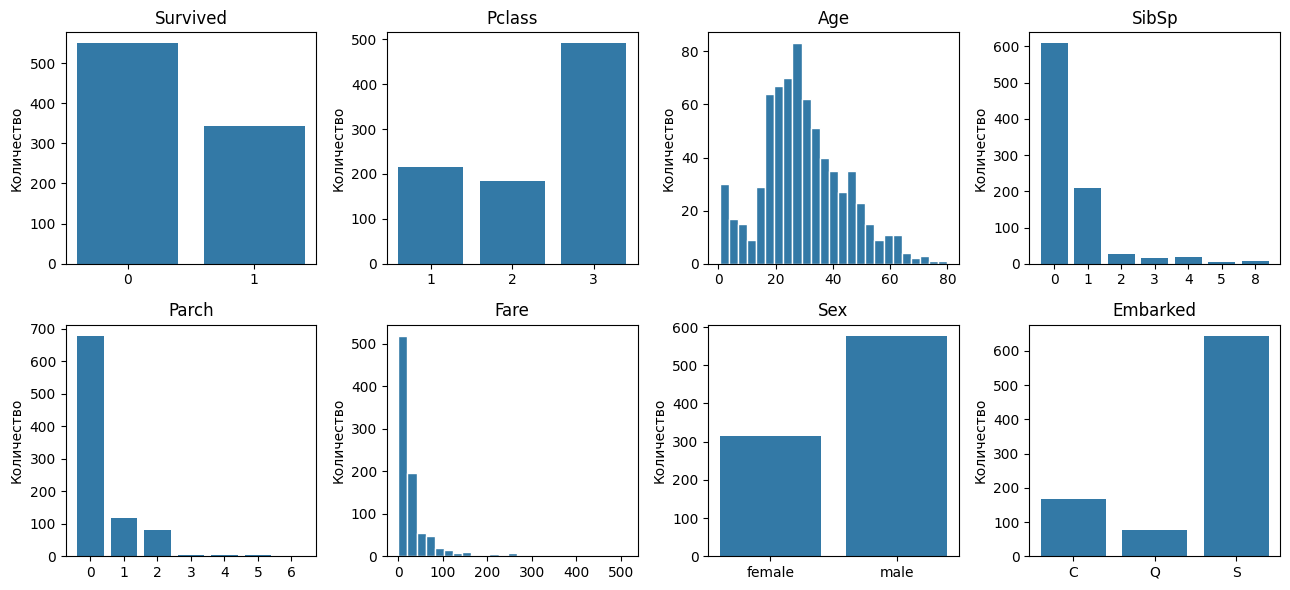

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
columns = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex', 'Embarked']
for ax, col in zip(axes.flat, columns):
    values = df[col].dropna()
    if col in ['Age', 'Fare']:
        ax.hist(values, bins=25, color='#3379a6', edgecolor='white')
    else:
        counts = values.value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color='#3379a6')
    ax.set_title(col)
    ax.set_ylabel('Количество')
fig.tight_layout()
plt.show()


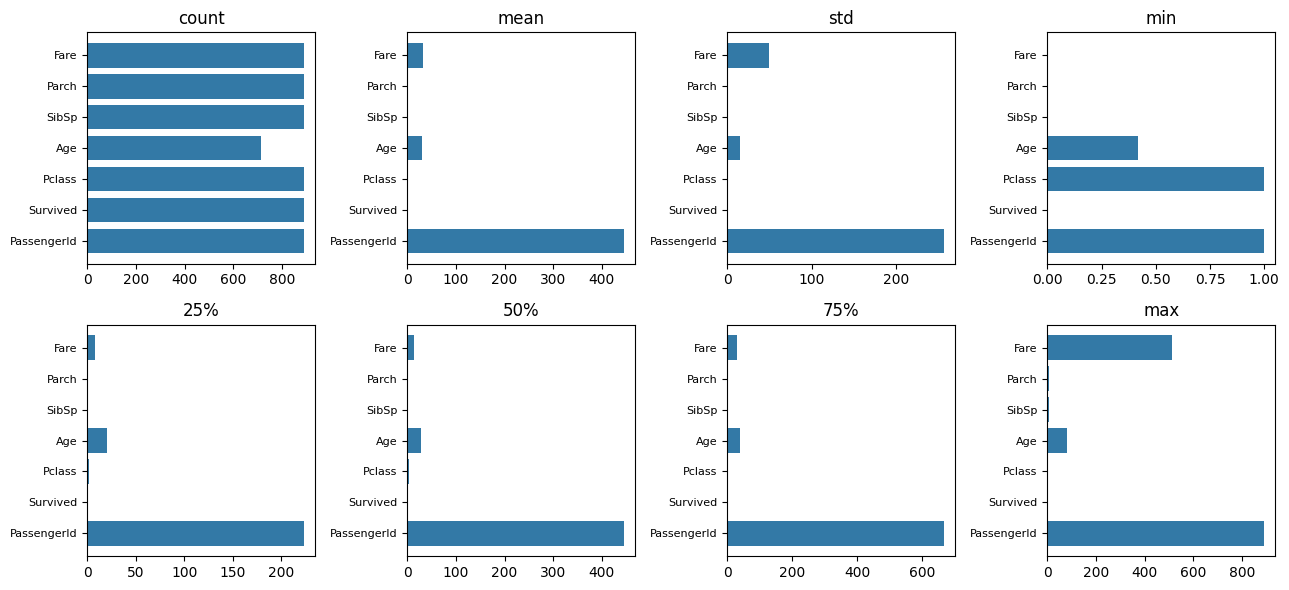

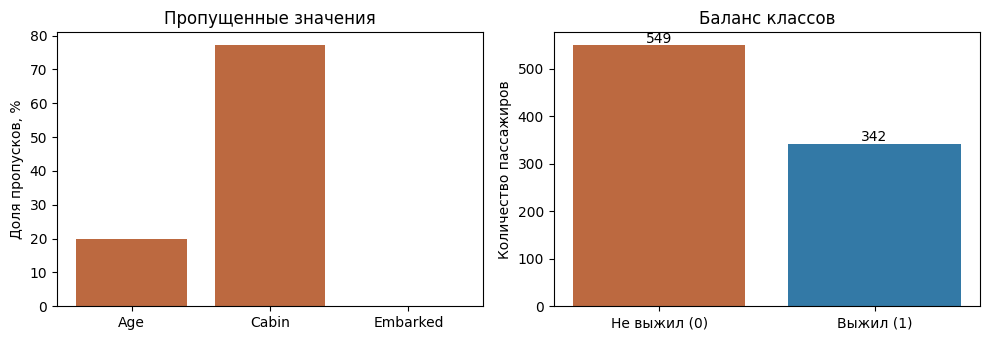

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, stat in zip(axes.flat, stats.columns):
    ax.barh(stats.index, stats[stat], color='#3379a6')
    ax.set_title(stat)
    ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
nonzero = missing[missing['Количество'] > 0]
axes[0].bar(nonzero.index, nonzero['Доля, %'], color='#bc6940')
axes[0].set_ylabel('Доля пропусков, %')
axes[0].set_title('Пропущенные значения')
class_counts = df.Survived.value_counts().sort_index()
axes[1].bar(['Не выжил (0)', 'Выжил (1)'], class_counts, color=['#bc6940', '#3379a6'])
axes[1].set_ylabel('Количество пассажиров')
axes[1].set_title('Баланс классов')
for i, n in enumerate(class_counts):
    axes[1].text(i, n + 5, str(n), ha='center')
fig.tight_layout()
plt.show()


In [41]:
target_col = 'Survived'
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
features = numeric_features + categorical_features

X_full = df[features].copy()
y_full = df[target_col].copy()

print(f"Числовые признаки: {numeric_features}")
print(f"Категориальные признаки: {categorical_features}")

Числовые признаки: ['Age', 'SibSp', 'Parch', 'Fare']
Категориальные признаки: ['Pclass', 'Sex', 'Embarked']


Не учитываются PassengerId, Name, Ticket и Cabin

In [42]:
def stratified_split(y, test_size=0.2, random_state=42):
    rng = np.random.default_rng(random_state)
    train, test = [], []
    for label in np.unique(y):
        indices = rng.permutation(np.flatnonzero(y == label))
        n_test = int(round(len(indices) * test_size))
        test.extend(indices[:n_test])
        train.extend(indices[n_test:])
    return rng.permutation(train), rng.permutation(test)


class TitanicPreprocessor:
    numeric = ['Age', 'SibSp', 'Parch', 'Fare']
    categorical = ['Pclass', 'Sex', 'Embarked']

    def fit(self, data):
        self.medians = data[self.numeric].median()
        numeric = data[self.numeric].fillna(self.medians)
        self.means = numeric.mean()
        self.scales = numeric.std(ddof=0).replace(0, 1)
        self.modes = {c: data[c].mode().iloc[0] for c in self.categorical}
        self.categories = {
            c: sorted(data[c].fillna(self.modes[c]).unique())
            for c in self.categorical
        }
        self.feature_names = self.numeric + [
            f'{c}_{value}' for c in self.categorical
            for value in self.categories[c][1:]
        ]
        return self

    def transform(self, data):
        numeric = data[self.numeric].fillna(self.medians)
        parts = [((numeric - self.means) / self.scales).to_numpy(float)]
        for c in self.categorical:
            values = data[c].fillna(self.modes[c])
            if not values.isin(self.categories[c]).all():
                raise ValueError(f'Unknown category in {c}')
            for value in self.categories[c][1:]:
                parts.append((values == value).to_numpy(float)[:, None])
        return np.column_stack(parts)

train_idx, test_idx = stratified_split(df.Survived.to_numpy(), random_state=42)
train, test = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
assert not set(train.PassengerId) & set(test.PassengerId)
preprocessor = TitanicPreprocessor().fit(train)
X_train, X_test = preprocessor.transform(train), preprocessor.transform(test)
y_train, y_test = train.Survived.to_numpy(), test.Survived.to_numpy()
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert np.allclose(X_train[:, :4].mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_train[:, :4].std(axis=0), 1)
split_info = pd.DataFrame({
    'size': [len(train), len(test)],
    'not_survived': [(y_train == 0).sum(), (y_test == 0).sum()],
    'survived': [(y_train == 1).sum(), (y_test == 1).sum()],
}, index=['train', 'test'])
print(f"Размер обучающей выборки (Train): {X_train.shape[0]} строк")
print(f"Размер тестовой выборки (Test):   {X_test.shape[0]} строк")
display(split_info)
print('Признаки:', preprocessor.feature_names)
print('Медианы train:', preprocessor.medians.to_dict())


Размер обучающей выборки (Train): 713 строк
Размер тестовой выборки (Test):   178 строк


,size,not_survived,survived
train,713,439,274
test,178,110,68


Признаки: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']
Медианы train: {'Age': 28.0, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 14.4542}


In [43]:
class CustomLogisticRegression:
    def __init__(self, learning_rate=0.1, max_iter=1000,
                 optimizer='gd', tol=1e-8):
        if learning_rate <= 0 or max_iter < 1 or optimizer not in ('gd', 'newton'):
            raise ValueError('Invalid hyperparameters')
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.optimizer = optimizer
        self.tol = tol

    @staticmethod
    def sigmoid(z):
        z = np.asarray(z, dtype=float)
        out = np.empty_like(z)
        positive = z >= 0
        out[positive] = 1 / (1 + np.exp(-z[positive]))
        exp_z = np.exp(z[~positive])
        out[~positive] = exp_z / (1 + exp_z)
        return out

    @staticmethod
    def log_loss(y, logits):
        return float(np.mean(np.logaddexp(0, logits) - y * logits))

    def fit(self, X, y):
        design = np.column_stack([np.ones(len(X)), X])
        y = np.asarray(y, dtype=float)
        self.weights = np.zeros(design.shape[1])
        self.loss_history = [self.log_loss(y, design @ self.weights)]
        self.n_iter = 0
        self.converged = False
        for _ in range(self.max_iter):
            probabilities = self.sigmoid(design @ self.weights)
            gradient = design.T @ (probabilities - y) / len(y)
            if np.max(np.abs(gradient)) <= self.tol:
                self.converged = True
                break
            if self.optimizer == 'gd':
                direction = gradient
            else:
                curvature = probabilities * (1 - probabilities)
                hessian = design.T @ (design * curvature[:, None]) / len(y)
                direction = np.linalg.pinv(hessian) @ gradient
            self.weights -= self.learning_rate * direction
            loss = self.log_loss(y, design @ self.weights)
            if not np.isfinite(loss):
                raise FloatingPointError('Non-finite training loss')
            self.loss_history.append(loss)
            self.n_iter += 1
        gradient = design.T @ (self.predict_proba(X) - y) / len(y)
        self.gradient_norm = float(np.max(np.abs(gradient)))
        self.converged = self.gradient_norm <= self.tol
        return self

    def decision_function(self, X):
        return self.weights[0] + np.asarray(X) @ self.weights[1:]

    def predict_proba(self, X):
        return self.sigmoid(self.decision_function(X))

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)


    def print_equation(self, feature_names):
        equation = f"z = {self.weights[0]:.4f}"
        for name, weight in zip(feature_names, self.weights[1:]):
            sign = '+' if weight >= 0 else '-'
            equation += f" {sign} {abs(weight):.4f}*{name}"
        print("Логистическая модель в скалярном виде:")
        print(equation)
        print("p(y=1) = 1 / (1 + exp(-z))")


def classification_metrics(y, prediction):
    y, prediction = np.asarray(y), np.asarray(prediction)
    tp = int(np.sum((y == 1) & (prediction == 1)))
    tn = int(np.sum((y == 0) & (prediction == 0)))
    fp = int(np.sum((y == 0) & (prediction == 1)))
    fn = int(np.sum((y == 1) & (prediction == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(accuracy=(tp + tn) / len(y), precision=precision,
                recall=recall, f1=f1, tp=tp, tn=tn, fp=fp, fn=fn)


In [44]:
LEARNING_RATES = [0.01, 0.1, 0.5, 1.0]
ITERATIONS = [10, 100, 1000]
OPTIMIZERS = ['gd', 'newton']
records, models = [], {}

for learning_rate in LEARNING_RATES:
    for max_iter in ITERATIONS:
        model = CustomLogisticRegression(learning_rate, max_iter, 'gd')
        start = perf_counter()
        model.fit(X_train, y_train)
        elapsed = (perf_counter() - start) * 1000
        y_pred = model.predict(X_test)
        metrics = classification_metrics(y_test, y_pred)
        models[('gd', learning_rate, max_iter)] = model
        records.append(dict(
            optimizer='gd', learning_rate=learning_rate,
            max_iter=max_iter, n_iter=model.n_iter, converged=model.converged,
            gradient_norm=model.gradient_norm, time_ms=elapsed,
            train_log_loss=model.loss_history[-1],
            test_log_loss=model.log_loss(y_test, model.decision_function(X_test)),
            **metrics
        ))

print("Градиентнаый спуск")
results_gd = pd.DataFrame([r for r in records if r['optimizer'] == 'gd'])
display(results_gd[[
    'learning_rate', 'max_iter', 'n_iter', 'accuracy',
    'precision', 'recall', 'f1', 'test_log_loss'
]].round(6))


Градиентнаый спуск


,learning_rate,max_iter,n_iter,accuracy,precision,recall,f1,test_log_loss
0,0.01,10,10,0.646067,0.777778,0.102941,0.181818,0.682996
1,0.01,100,100,0.651685,0.800000,0.117647,0.205128,0.625236
2,0.01,1000,1000,0.724719,0.806452,0.367647,0.505051,0.529503
3,0.10,10,10,0.651685,0.800000,0.117647,0.205128,0.624413
4,0.10,100,100,0.724719,0.806452,0.367647,0.505051,0.529418
5,0.10,1000,1000,0.814607,0.796610,0.691176,0.740157,0.441004
6,0.50,10,10,0.679775,0.789474,0.220588,0.344828,0.558569
7,0.50,100,100,0.814607,0.818182,0.661765,0.731707,0.458494
8,0.50,1000,1000,0.803371,0.770492,0.691176,0.728682,0.423509
9,1.00,10,10,0.724719,0.806452,0.367647,0.505051,0.528564


In [45]:
for learning_rate in LEARNING_RATES:
    for max_iter in ITERATIONS:
        model = CustomLogisticRegression(learning_rate, max_iter, 'newton')
        start = perf_counter()
        model.fit(X_train, y_train)
        elapsed = (perf_counter() - start) * 1000
        y_pred = model.predict(X_test)
        metrics = classification_metrics(y_test, y_pred)
        models[('newton', learning_rate, max_iter)] = model
        records.append(dict(
            optimizer='newton', learning_rate=learning_rate,
            max_iter=max_iter, n_iter=model.n_iter, converged=model.converged,
            gradient_norm=model.gradient_norm, time_ms=elapsed,
            train_log_loss=model.loss_history[-1],
            test_log_loss=model.log_loss(y_test, model.decision_function(X_test)),
            **metrics
        ))

print("Метод Ньютона")
results_newton = pd.DataFrame([r for r in records if r['optimizer'] == 'newton'])
display(results_newton[[
    'learning_rate', 'max_iter', 'n_iter', 'accuracy',
    'precision', 'recall', 'f1', 'test_log_loss'
]].round(6))


Метод Ньютона


,learning_rate,max_iter,n_iter,accuracy,precision,recall,f1,test_log_loss
0,0.01,10,10,0.797753,0.750000,0.705882,0.727273,0.651648
1,0.01,100,100,0.803371,0.761905,0.705882,0.732824,0.478496
2,0.01,1000,1000,0.792135,0.754098,0.676471,0.713178,0.422789
3,0.10,10,10,0.803371,0.761905,0.705882,0.732824,0.475740
4,0.10,100,100,0.792135,0.754098,0.676471,0.713178,0.422789
5,0.10,1000,161,0.792135,0.754098,0.676471,0.713178,0.422788
6,0.50,10,10,0.792135,0.754098,0.676471,0.713178,0.422817
7,0.50,100,25,0.792135,0.754098,0.676471,0.713178,0.422788
8,0.50,1000,25,0.792135,0.754098,0.676471,0.713178,0.422788
9,1.00,10,5,0.792135,0.754098,0.676471,0.713178,0.422788


In [46]:
summary_df = pd.DataFrame(records)
results = summary_df
ranked = summary_df.sort_values(
    ['f1', 'accuracy', 'test_log_loss', 'max_iter'],
    ascending=[False, False, True, True], kind='stable'
)
best = ranked.iloc[0]
best_model = models[(best.optimizer, float(best.learning_rate), int(best.max_iter))]
y_pred = best_model.predict(X_test)

print("Итоговое сравнение")
display(summary_df[[
    'optimizer', 'learning_rate', 'max_iter', 'n_iter',
    'accuracy', 'precision', 'recall', 'f1', 'test_log_loss'
]].round(6))

print("--- Наилучшая конфигурация ---")
print(f"Метод: {best.optimizer}")
print(f"Коэффициент обучения: {best.learning_rate:g}")
print(f"Количество итераций: {int(best.max_iter)}")
print(f"Признаки: {preprocessor.feature_names}")
best_model.print_equation(preprocessor.feature_names)
print("\nОценки параметров (Вектор B):")
print(f"Свободный член (a): {best_model.weights[0]:.4f}")
for name, weight in zip(preprocessor.feature_names, best_model.weights[1:]):
    print(f"Коэффициент при {name}: {weight:.4f}")
print("-" * 30)
print(f"Accuracy:  {best.accuracy:.5f}")
print(f"Precision: {best.precision:.5f}")
print(f"Recall:    {best.recall:.5f}")
print(f"F1-Score:  {best.f1:.5f}")
print("Первые 5 вероятностей:      ", np.round(best_model.predict_proba(X_test)[:5], 4))
print("Первые 5 предсказаний:      ", y_pred[:5])
print("Первые 5 реальных значений:", y_test[:5])

benchmarks = []
for optimizer in OPTIMIZERS:
    times, counts = [], []
    for repeat in range(7):
        model = CustomLogisticRegression(1.0, 1000, optimizer)
        start = perf_counter()
        model.fit(X_train, y_train)
        times.append((perf_counter() - start) * 1000)
        counts.append(model.n_iter)
    benchmarks.append(dict(optimizer=optimizer, learning_rate=1.0, max_iter=1000,
                           median_time_ms=float(np.median(times)),
                           n_iter=counts[-1], train_log_loss=model.loss_history[-1],
                           gradient_norm=model.gradient_norm, converged=model.converged))
benchmark = pd.DataFrame(benchmarks)
print('\nСравнение времени (медиана 7 запусков):')
display(benchmark)


Итоговое сравнение


,optimizer,learning_rate,max_iter,n_iter,accuracy,precision,recall,f1,test_log_loss
0,gd,0.01,10,10,0.646067,0.777778,0.102941,0.181818,0.682996
1,gd,0.01,100,100,0.651685,0.800000,0.117647,0.205128,0.625236
2,gd,0.01,1000,1000,0.724719,0.806452,0.367647,0.505051,0.529503
3,gd,0.10,10,10,0.651685,0.800000,0.117647,0.205128,0.624413
4,gd,0.10,100,100,0.724719,0.806452,0.367647,0.505051,0.529418
5,gd,0.10,1000,1000,0.814607,0.796610,0.691176,0.740157,0.441004
6,gd,0.50,10,10,0.679775,0.789474,0.220588,0.344828,0.558569
7,gd,0.50,100,100,0.814607,0.818182,0.661765,0.731707,0.458494
8,gd,0.50,1000,1000,0.803371,0.770492,0.691176,0.728682,0.423509
9,gd,1.00,10,10,0.724719,0.806452,0.367647,0.505051,0.528564


--- Наилучшая конфигурация ---
Метод: gd
Коэффициент обучения: 1
Количество итераций: 100
Признаки: ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']
Логистическая модель в скалярном виде:
z = 1.4870 - 0.4464*Age - 0.4347*SibSp - 0.0104*Parch + 0.4960*Fare + 0.0315*Pclass_2 - 0.9167*Pclass_3 - 2.2790*Sex_male + 0.1210*Embarked_Q - 0.1901*Embarked_S
p(y=1) = 1 / (1 + exp(-z))

Оценки параметров (Вектор B):
Свободный член (a): 1.4870
Коэффициент при Age: -0.4464
Коэффициент при SibSp: -0.4347
Коэффициент при Parch: -0.0104
Коэффициент при Fare: 0.4960
Коэффициент при Pclass_2: 0.0315
Коэффициент при Pclass_3: -0.9167
Коэффициент при Sex_male: -2.2790
Коэффициент при Embarked_Q: 0.1210
Коэффициент при Embarked_S: -0.1901
------------------------------
Accuracy:  0.81461
Precision: 0.79661
Recall:    0.69118
F1-Score:  0.74016
Первые 5 вероятностей:       [0.0485 0.316  0.5303 0.0632 0.739 ]
Первые 5 предсказаний:       [0 0 1 0 1]
Первые 5 р

,optimizer,learning_rate,max_iter,median_time_ms,n_iter,train_log_loss,gradient_norm,converged
0,gd,1.0,1000,117.806196,1000,0.447638,6.371617e-05,False
1,newton,1.0,1000,1.709962,5,0.447637,1.652610e-11,True


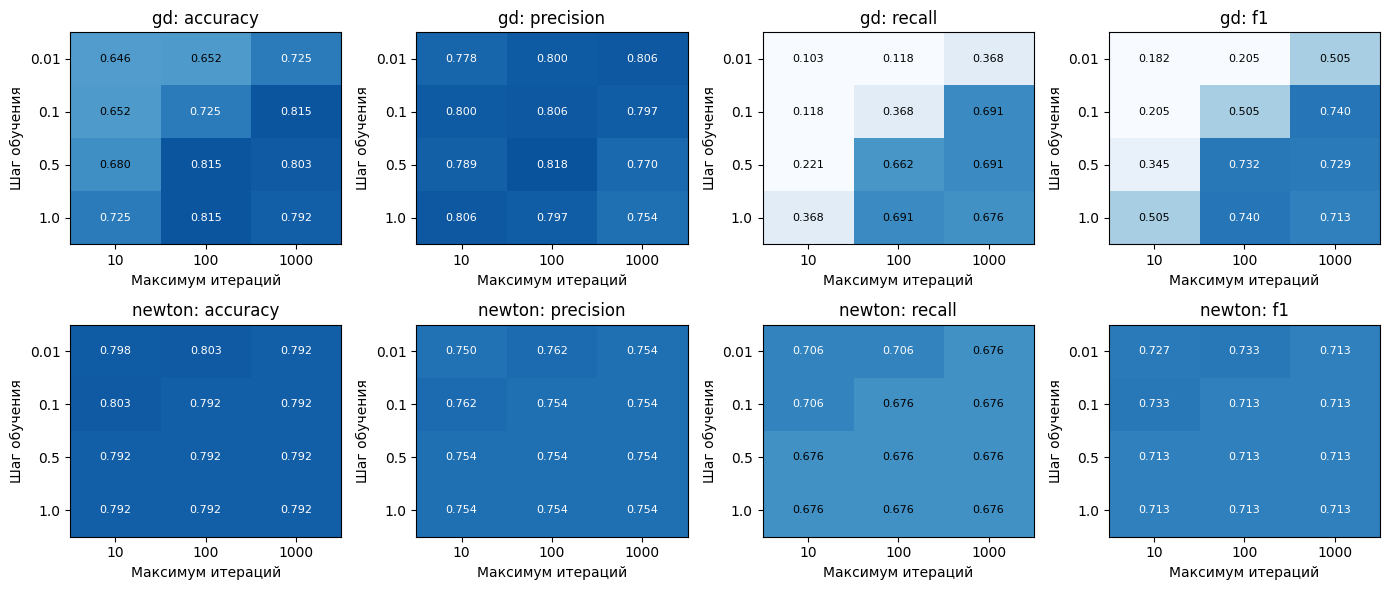

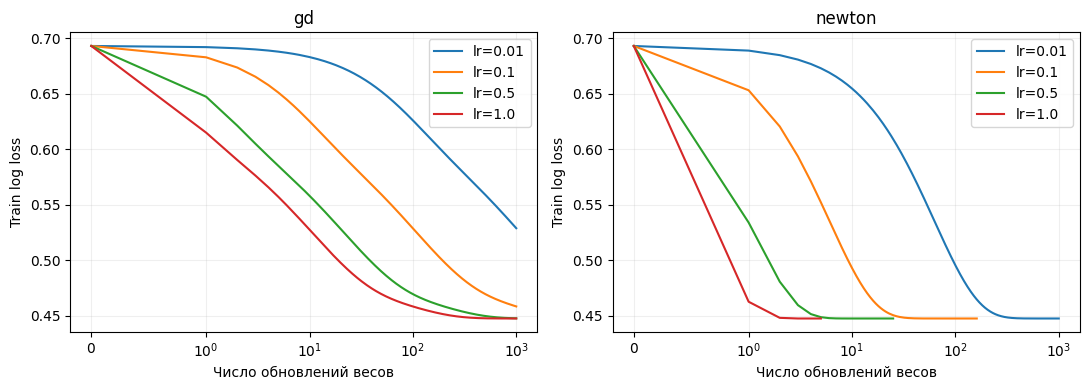

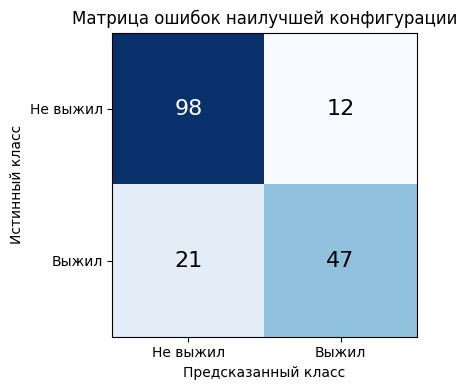

In [35]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for row, optimizer in enumerate(OPTIMIZERS):
    for col, metric in enumerate(['accuracy', 'precision', 'recall', 'f1']):
        ax = axes[row, col]
        matrix = results[results.optimizer == optimizer].pivot(
            index='learning_rate', columns='max_iter', values=metric)
        ax.imshow(matrix, vmin=0.3, vmax=0.9, cmap='Blues', aspect='auto')
        ax.set_xticks(range(len(ITERATIONS)), ITERATIONS)
        ax.set_yticks(range(len(LEARNING_RATES)), LEARNING_RATES)
        ax.set_title(f'{optimizer}: {metric}')
        ax.set_xlabel('Максимум итераций')
        ax.set_ylabel('Шаг обучения')
        for i in range(len(LEARNING_RATES)):
            for j in range(len(ITERATIONS)):
                v = matrix.iloc[i, j]
                ax.text(j, i, f'{v:.3f}', ha='center', va='center',
                        color='white' if v > 0.7 else 'black', fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, optimizer in zip(axes, OPTIMIZERS):
    for lr in LEARNING_RATES:
        model = models[(optimizer, lr, 1000)]
        ax.plot(np.arange(len(model.loss_history)), model.loss_history, label=f'lr={lr}')
    ax.set_xscale('symlog', linthresh=1)
    ax.set_xlabel('Число обновлений весов')
    ax.set_ylabel('Train log loss')
    ax.set_title(optimizer)
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

prediction = best_model.predict(X_test)
metrics = classification_metrics(y_test, prediction)
confusion = np.array([[metrics['tn'], metrics['fp']], [metrics['fn'], metrics['tp']]])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(confusion, cmap='Blues')
ax.set_xticks([0, 1], ['Не выжил', 'Выжил'])
ax.set_yticks([0, 1], ['Не выжил', 'Выжил'])
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
ax.set_title('Матрица ошибок наилучшей конфигурации')
for (i, j), value in np.ndenumerate(confusion):
    ax.text(j, i, str(value), ha='center', va='center', fontsize=16,
            color='white' if value > confusion.max() / 2 else 'black')
fig.tight_layout()
plt.show()